In [11]:
import json
import os
import re
import time
import unicodedata
from datetime import datetime, timezone
from pathlib import Path

import ftfy
import pandas as pd
import requests
from lingua import Language, LanguageDetectorBuilder
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

BASE_URL = "https://openlibrary.org"
HEADERS = {"User-Agent": "AdvancedDataMining/1.0 (your-email@example.com)"}
# `language:eng` makes Open Library return the matching English edition of each work
SEARCH_QUERY = "subject:fiction language:eng"
SEARCH_FIELDS = "key,title,author_name,description,subject,editions,editions.key,editions.title,editions.language"
N_BOOKS = 20_000  # target number of English books (after filtering)
BATCH_SIZE = 50
REQUEST_DELAY = 1.0

RAW_DIR = Path("data/raw/batches_eng")
PROGRESS_PATH = RAW_DIR / "_progress.json"
PROCESSED_DIR = Path("data/processed")
JSON_PATH = PROCESSED_DIR / "books.json"
PARQUET_PATH = PROCESSED_DIR / "books.parquet"

session = requests.Session()
session.headers.update(HEADERS)
retry = Retry(total=5, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504], allowed_methods=["GET"])
session.mount("https://", HTTPAdapter(max_retries=retry))

In [6]:
# English-only filter:
# 1. Open Library must return an edition catalogued as English only (language == ["eng"]);
#    its title is used as the book name, e.g. "O Alquimista" -> "The Alchemist".
# 2. The (work-level) description must be detected as English.
ENGLISH_CODE = "eng"

# Languages that steal short/mixed English texts, excluded from description detection
NOISY_LANGUAGES = [
    Language.LATIN, Language.ESPERANTO, Language.SOMALI, Language.SWAHILI, Language.TSWANA,
    Language.SOTHO, Language.XHOSA, Language.ZULU, Language.TSONGA, Language.YORUBA,
    Language.SHONA, Language.GANDA, Language.MAORI, Language.TAGALOG, Language.WELSH,
    Language.IRISH, Language.AFRIKAANS, Language.BASQUE, Language.ALBANIAN, Language.NYNORSK,
    Language.CATALAN,
]
description_detector = LanguageDetectorBuilder.from_all_languages_without(*NOISY_LANGUAGES).build()


def get_description(doc):
    description = doc.get("description")
    if isinstance(description, dict):
        description = description.get("value")
    return (description or "").strip()


def get_english_edition(doc):
    """The edition Open Library matched for `language:eng`, if it is English-only."""
    editions = (doc.get("editions") or {}).get("docs", [])
    if editions and editions[0].get("language") == [ENGLISH_CODE] and editions[0].get("title"):
        return editions[0]
    return None


def is_latin_script(text):
    return all(not ch.isalpha() or "LATIN" in unicodedata.name(ch, "") for ch in text)


def is_english_description(description):
    return bool(description) and description_detector.detect_language_of(description[:2000]) == Language.ENGLISH


def is_english_book(doc):
    edition = get_english_edition(doc)
    return (
        edition is not None
        and is_latin_script(edition["title"])
        and is_english_description(get_description(doc))
    )


# Sanity check
english_edition = {"docs": [{"title": "Dune", "language": ["eng"]}]}
bilingual_edition = {"docs": [{"title": "El Principito / The Little Prince", "language": ["spa", "eng"]}]}
for label, doc in [
    ("English", {"editions": english_edition, "description": "Set on the desert planet Arrakis, Dune is the story of Paul Atreides."}),
    ("bilingual edition", {"editions": bilingual_edition, "description": "A pilot stranded in the desert meets a young prince."}),
    ("French description", {"editions": english_edition, "description": "Le Petit Prince est une œuvre de langue française."}),
]:
    print(f"{label:20} -> {is_english_book(doc)}")

English              -> True
bilingual edition    -> False
French description   -> False


In [7]:
def batch_path(batch_no):
    return RAW_DIR / f"batch_{batch_no:05d}.jsonl"


def atomic_write(path, text):
    """Write via a temp file + rename, so a crash never leaves a half-written file."""
    tmp_path = path.with_name(path.name + ".tmp")
    with tmp_path.open("w", encoding="utf-8") as f:
        f.write(text)
        f.flush()
        os.fsync(f.fileno())
    tmp_path.replace(path)


def batch_docs(path):
    docs = []
    with path.open(encoding="utf-8") as f:
        for line in f:
            docs.extend(json.loads(json.loads(line)["response"]).get("docs", []))
    return docs


def load_progress():
    """batch_no -> list of English work keys found in that batch."""
    if PROGRESS_PATH.exists():
        return {int(k): v for k, v in json.loads(PROGRESS_PATH.read_text(encoding="utf-8")).items()}
    return {}


def save_progress(progress):
    atomic_write(PROGRESS_PATH, json.dumps({str(k): v for k, v in sorted(progress.items())}))


def fetch_batch(batch_no):
    """Download one search page and land the raw, unedited response as JSONL."""
    offset = batch_no * BATCH_SIZE
    response = session.get(
        f"{BASE_URL}/search.json",
        params={
            "q": SEARCH_QUERY,
            "fields": SEARCH_FIELDS,
            "sort": "readinglog",
            "limit": BATCH_SIZE,
            "offset": offset,
        },
        timeout=(10, 120),
    )
    response.raise_for_status()
    record = {
        "batch_no": batch_no,
        "offset": offset,
        "url": response.url,
        "status_code": response.status_code,
        "fetched_at": datetime.now(timezone.utc).isoformat(),
        "response": response.text,
    }
    atomic_write(batch_path(batch_no), json.dumps(record, ensure_ascii=False) + "\n")
    return json.loads(response.text).get("docs", [])


def download_all():
    """Fetch batches until N_BOOKS unique English books are landed.

    Safe to stop at any time: finished batches are kept on disk and skipped on the next run.
    """
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    for tmp in RAW_DIR.glob("*.tmp"):
        tmp.unlink()

    progress = load_progress()
    english_keys = set()
    batch_no = 0
    started = time.time()
    while len(english_keys) < N_BOOKS:
        path = batch_path(batch_no)
        if batch_no in progress and path.exists():
            english_keys.update(progress[batch_no])
            batch_no += 1
            continue

        if path.exists():
            docs = batch_docs(path)  # landed, but progress not saved before the stop
        else:
            docs = fetch_batch(batch_no)
            time.sleep(REQUEST_DELAY)
        if not docs:
            print("No more search results.")
            break

        progress[batch_no] = [doc["key"] for doc in docs if is_english_book(doc)]
        save_progress(progress)
        english_keys.update(progress[batch_no])
        print(
            f"batch {batch_no:05d} | +{len(progress[batch_no]):>2}/{len(docs)} English"
            f" | {len(english_keys):>6}/{N_BOOKS} | {time.time() - started:6.0f}s",
            flush=True,
        )
        batch_no += 1
    print(f"Done: {len(english_keys)} English books from {batch_no} batches in {RAW_DIR}")

In [8]:
download_all()

batch 00000 | +47/50 English |     47/20000 |      4s
batch 00001 | +48/50 English |     95/20000 |      7s
batch 00002 | +46/50 English |    141/20000 |     11s
batch 00003 | +49/50 English |    190/20000 |     14s
batch 00004 | +47/50 English |    237/20000 |     17s
batch 00005 | +46/50 English |    283/20000 |     20s
batch 00006 | +47/50 English |    330/20000 |     23s
batch 00007 | +46/50 English |    376/20000 |     26s
batch 00008 | +45/50 English |    421/20000 |     29s
batch 00009 | +47/50 English |    468/20000 |     32s
batch 00010 | +47/50 English |    515/20000 |     35s
batch 00011 | +46/50 English |    561/20000 |     38s
batch 00012 | +46/50 English |    607/20000 |     41s
batch 00013 | +46/50 English |    653/20000 |     44s
batch 00014 | +48/50 English |    701/20000 |     47s
batch 00015 | +48/50 English |    749/20000 |     50s
batch 00016 | +47/50 English |    796/20000 |     53s
batch 00017 | +48/50 English |    844/20000 |     56s
batch 00018 | +48/50 English

Total books: 20,000
Books with at least one selected genre: 17,543
Books with no matching selected genre (unlisted): 2,457

Books per genre:
Crime/Mystery: 2,570
Romance: 6,293
Fantasy: 2,915
Contemporary: 2,535
Science Fiction: 1,915
Action/Adventure: 2,071
Horror: 1,279
Literary: 674
Comedy: 1,075
Children Books: 7,069
Historical: 2,865
Non-fiction: 218
unlisted: 2,457

Before matching, tags are lowercased, Unicode-repaired, stripped of punctuation and invisible characters, and whitespace-normalized.
Empty tags and duplicates created by cleaning are removed.
Matching uses normalized category words within existing tags and the explicit mappings below.
Crime or mystery -> Crime/Mystery; action or adventure -> Action/Adventure.
Non-fiction, non fiction, and nonfiction -> Non-fiction.
Children, children's, or juvenile -> Children Books; comedy or humorous -> Comedy.
Catalog metadata tags are ignored when matching selected genres.
Matched books keep only selected genres; all other tags ar

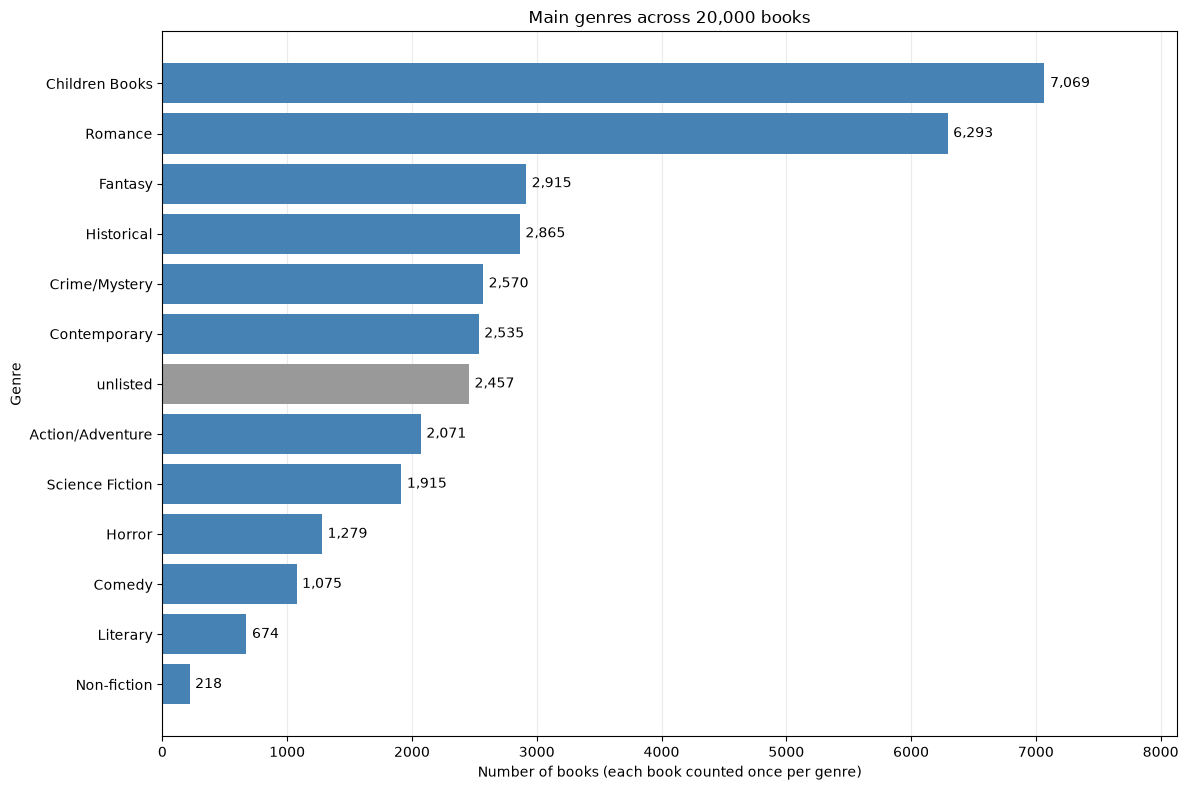

Saved:
data/processed/books_selected_genres.json
data/processed/books_selected_genres.parquet
data/processed/selected_genre_counts.txt
data/processed/selected_genre_popularity.png


In [7]:
import re
import unicodedata
from pathlib import Path

import ftfy
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

PROCESSED_DIR = Path("data/processed")
UNLISTED = "unlisted"
GENRE_PATTERNS = {
    "Crime/Mystery": r"\b(?:crime|mystery)\b",
    "Romance": r"\bromance\b",
    "Fantasy": r"\bfantasy\b",
    "Contemporary": r"\bcontemporary\b",
    "Science Fiction": r"\bscience fiction\b",
    "Action/Adventure": r"\b(?:action|adventure)\b",
    "Horror": r"\bhorror\b",
    "Literary": r"\bliterary\b",
    "Comedy": r"\b(?:comedy|humorous)\b",
    "Children Books": r"\b(?:children|childrens|juvenile)\b",
    "Historical": r"\bhistorical\b",
    "Non-fiction": r"\b(?:non fiction|nonfiction)\b",
}
GENRE_RULES = {genre: re.compile(pattern) for genre, pattern in GENRE_PATTERNS.items()}
CATALOG_PREFIX = re.compile(r"^(?:collectionid|collection|nyt|series|serie|reading level)\b")


def normalize_genre(label: str) -> str:
    text = ftfy.fix_text(label, normalization="NFKC").casefold()
    text = "".join(ch for ch in text if unicodedata.category(ch) != "Cf")
    text = re.sub(r"['\u2018\u2019]", "", text)
    text = re.sub(r"[^\w\s]|_", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def assign_main_genres(tags: list[str]) -> list[str]:
    """Clean tags first; keep only selected genres on a match, otherwise append unlisted."""
    if not isinstance(tags, list) or any(not isinstance(tag, str) for tag in tags):
        raise TypeError("Each book's genres must be a list of strings.")
    cleaned_tags = list(dict.fromkeys(label for tag in tags if (label := normalize_genre(tag))))
    labels = [label for label in cleaned_tags if not CATALOG_PREFIX.match(label)]
    matches = [
        genre
        for genre, pattern in GENRE_RULES.items()
        if any(pattern.search(label) for label in labels)
    ]
    return matches if matches else list(dict.fromkeys([*cleaned_tags, UNLISTED]))


books = pd.read_json(PROCESSED_DIR / "books.json")
if books.empty:
    raise ValueError("The source book dataset is empty.")
if books["work_key"].isna().any() or books["work_key"].duplicated().any():
    raise ValueError("Expected one non-null, unique work_key per book.")

classified = books.copy()
classified["genres"] = books["genres"].map(assign_main_genres)
counts = (
    classified["genres"].map(lambda tags: list(dict.fromkeys(tags))).explode().value_counts()
    .reindex([*GENRE_RULES, UNLISTED], fill_value=0)
)
json_path = PROCESSED_DIR / "books_selected_genres.json"
parquet_path = PROCESSED_DIR / "books_selected_genres.parquet"
report_path = PROCESSED_DIR / "selected_genre_counts.txt"
chart_path = PROCESSED_DIR / "selected_genre_popularity.png"

classified.to_json(json_path, orient="records", force_ascii=False, indent=2)
classified.to_parquet(parquet_path, engine="pyarrow", index=False)

unlisted_count = int(counts[UNLISTED])
lines = [
    f"Total books: {len(classified):,}",
    f"Books with at least one selected genre: {len(classified) - unlisted_count:,}",
    f"Books with no matching selected genre ({UNLISTED}): {unlisted_count:,}",
    "",
    "Books per genre:",
    *[f"{genre}: {count:,}" for genre, count in counts.items()],
    "",
    "Before matching, tags are lowercased, Unicode-repaired, stripped of punctuation and invisible characters, and whitespace-normalized.",
    "Empty tags and duplicates created by cleaning are removed.",
    "Matching uses normalized category words within existing tags and the explicit mappings below.",
    "Crime or mystery -> Crime/Mystery; action or adventure -> Action/Adventure.",
    "Non-fiction, non fiction, and nonfiction -> Non-fiction.",
    "Children, children's, or juvenile -> Children Books; comedy or humorous -> Comedy.",
    "Catalog metadata tags are ignored when matching selected genres.",
    "Matched books keep only selected genres; all other tags are removed.",
    "Unmatched books retain their cleaned tags and gain unlisted exactly once.",
    "The source books.json and books.parquet files are not modified.",
    "A book can have multiple genres, but counts only once per genre.",
    "Genre counts therefore need not sum to the total number of books.",
]
report = "\n".join(lines) + "\n"
report_path.write_text(report, encoding="utf-8")
print(report)

plot_counts = counts.sort_values(ascending=False, kind="stable")
fig, ax = plt.subplots(figsize=(12, 8))
colors = ["#999999" if genre == UNLISTED else "steelblue" for genre in plot_counts.index]
bars = ax.barh(plot_counts.index, plot_counts.values, color=colors)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{count:,}" for count in plot_counts], padding=4)
ax.set(
    title=f"Main genres across {len(classified):,} books",
    xlabel="Number of books (each book counted once per genre)",
    ylabel="Genre",
)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.margins(x=0.15)
fig.tight_layout()
fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved:\n{json_path}\n{parquet_path}\n{report_path}\n{chart_path}")

In [8]:
from pathlib import Path

import pandas as pd

selected_books = pd.read_json(Path("data/processed/books_selected_genres.json"))
unlisted_books = selected_books.loc[selected_books["genres"].map(lambda tags: "unlisted" in tags)]
unlisted_tags = unlisted_books[["work_key", "genres"]].explode("genres").dropna(subset=["genres"])
unlisted_tags = unlisted_tags.loc[~unlisted_tags["genres"].isin(["unlisted", ""])]
unlisted_tag_counts = (
    unlisted_tags.drop_duplicates(["work_key", "genres"])
    .groupby("genres").size().rename("book_count").reset_index(name="book_count")
    .rename(columns={"genres": "tag"})
    .sort_values(["book_count", "tag"], ascending=[False, True], ignore_index=True)
)
if unlisted_tag_counts.empty:
    raise ValueError("No tags other than 'unlisted' were found among unlisted books.")

highest_count = int(unlisted_tag_counts["book_count"].max())
most_common_unlisted_tags = unlisted_tag_counts.loc[unlisted_tag_counts["book_count"].eq(highest_count)]
print(f"Books labeled unlisted: {len(unlisted_books):,}")
print("Top 20 tags among unlisted books:")
unlisted_tag_counts.head(20)

Books labeled unlisted: 2,457
Top 20 tags among unlisted books:


,tag,book_count
0,fiction,1673
1,fiction general,1004
2,large type books,476
3,new york times bestseller,252
4,fiction in english,248
5,fiction psychological,176
6,social life and customs,162
7,literature,149
8,romans nouvelles,145
9,american fiction fictional works by one author,137
